# Figure S3 · terrain comparison family — short test

Adult/larva terrain contrasts included in the joint statistical family, although not displayed in S3.

The saved tables and figures below come from a real short test and can be viewed directly on GitHub. To regenerate them, use the **Python (FlyControl)** kernel; see [setup and notebook index](README.md). Run cells from top to bottom. This notebook executes the same six stages as the command-line workflow, with reduced budgets and one training seed. It keeps every configured method. **These are software checks, not paper results.**

First execution downloads versioned public inputs. Neural assays and multi-stage maze prerequisites can still take substantial time; “short” refers to the training budget, not a seconds-long demonstration. Generated checkpoints, data and figures stay under `runs/`.

Choose a fresh `RUN_DIR` after code/configuration changes or for an independent restart. A completed run can be inspected with the “Inspect the smoke outputs” cell without retraining.

## Settings

Launch Jupyter from the repository root or `notebooks/`. Select the installed FlyControl kernel before running.

`DEVICE` defaults to CPU. To use a GPU, set it to an available device (for example `cuda:0`) or launch Jupyter with `FLYCONTROL_NOTEBOOK_DEVICE=cuda:0`. The saved execution records the device actually used.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/flycontrol").is_dir()
)
sys.path.insert(0, str(ROOT / "notebooks"))
from notebook_utils import run_stage, show_outputs

CONFIG = 'development-terrain'
RUN_DIR = ROOT / "runs/notebooks" / CONFIG
DEVICE = os.environ.get("FLYCONTROL_NOTEBOOK_DEVICE", "cpu")
WORKERS = 1
print(f"SMOKE TEST: {CONFIG} | {DEVICE} | {RUN_DIR.relative_to(ROOT)}")


SMOKE TEST: development-terrain | cpu | runs/notebooks/development-terrain


## 1. Prepare

Download and checksum-verify public inputs, then resolve the reduced configuration. This cell always sets `--smoke`; all configured methods and the first training seed are retained.

In [2]:
run_stage("prepare", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: prepare** · 17.6 seconds · smoke test

Full execution log: `logs/notebook-prepare.log` within the run directory.

## 2. Train

Train fresh policies using the reduced budgets. This includes any prerequisites required by the selected experiment.

In [3]:
run_stage("train", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: train** · 204.7 seconds · smoke test

Full execution log: `logs/notebook-train.log` within the run directory.

## 3. Evaluate

Run the configured smoke evaluations in the real simulator, recording failures as well as successful episodes.

In [4]:
run_stage("evaluate", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: evaluate** · 226.3 seconds · smoke test

Full execution log: `logs/notebook-evaluate.log` within the run directory.

## 4. Probe

Run the configured neural assays. Experiments without a neural assay record that explicitly. Short-trained policies can fail the required histories; read the recorded exclusions.

In [5]:
run_stage("probe", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: probe** · 0.0 seconds · smoke test

Full execution log: `logs/notebook-probe.log` within the run directory.

## 5. Analyze

Aggregate the generated numerical records. Smoke outputs do not support the manuscript’s statistical conclusions.

In [6]:
run_stage("analyze", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: analyze** · 0.5 seconds · smoke test

Full execution log: `logs/notebook-analyze.log` within the run directory.

## 6. Plot

Create diagnostic panels, numerical sources and editable PDF/SVG figures from this run.

In [7]:
run_stage("plot", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: plot** · 7.2 seconds · smoke test

Full execution log: `logs/notebook-plot.log` within the run directory.

## Inspect the smoke outputs

Check completion and effective settings, then inspect sample tables and up to three generated figures. All files remain available in `RUN_DIR`.

**SMOKE TEST — not paper results.**

,experiment,methods,training seeds
0,development-terrain,"adult, larva",[0]


Source/configuration SHA-256: `eaab77b7c7f8b5c50e7015c4c1c15e9ce272e2e432760c88fcc2e24c7a48ea9f`

,stage,completed,elapsed seconds
0,prepare,True,17.63
1,train,True,204.71
2,evaluate,True,226.33
3,probe,True,0.00
4,analyze,True,0.55
5,plot,True,7.21


`analysis/seed_means.csv` (first eight rows)

,condition,train_seed,value,task,metric
0,adult,0,100.000000,gapped,passed
1,larva,0,100.000000,gapped,passed
2,adult,0,100.000000,gapped,survived
3,larva,0,100.000000,gapped,survived
4,adult,0,5.665179,gapped,forward_distance_mm
5,larva,0,4.174029,gapped,forward_distance_mm
6,adult,0,0.532877,gapped,max_lateral_mm
7,larva,0,1.121177,gapped,max_lateral_mm


`analysis/episodes.csv` (first eight rows)

,condition,training_seed,terrain,evaluation_seed,survived_0_5_s,reason,duration_s,forward_distance_mm,net_displacement_mm,max_lateral_mm,...,any_foot_enters_obstacle_zone,first_near_edge_x_mm,first_far_edge_x_mm,progress_definition,train_seed,passed,survived,value_mm,source,checkpoint_sha256
0,adult,0,gapped,100000,True,time_limit,0.5,5.665179,5.690186,0.532877,...,True,2.0,2.45,Thorax x coordinate reaches/passes fixed terra...,0,1,1,0.45,/data2/ysy/github/FlyControl/runs/notebooks/de...,6b86a0d1e142d8e82b3d8f91d7d5a026654572fb6dbe88...
1,adult,0,blocks,100000,True,time_limit,0.5,2.026527,2.039813,0.660494,...,True,2.0,3.43,Thorax x coordinate reaches/passes fixed terra...,0,0,1,0.15,/data2/ysy/github/FlyControl/runs/notebooks/de...,6b86a0d1e142d8e82b3d8f91d7d5a026654572fb6dbe88...
2,larva,0,gapped,100000,True,time_limit,0.5,4.174029,4.259752,1.121177,...,True,2.0,2.45,Thorax x coordinate reaches/passes fixed terra...,0,1,1,0.45,/data2/ysy/github/FlyControl/runs/notebooks/de...,396d66f0bbad6a469641810039f792303dddf72a9bd1f6...
3,larva,0,blocks,100000,True,time_limit,0.5,2.126356,2.169863,0.714674,...,True,2.0,3.43,Thorax x coordinate reaches/passes fixed terra...,0,0,1,0.15,/data2/ysy/github/FlyControl/runs/notebooks/de...,396d66f0bbad6a469641810039f792303dddf72a9bd1f6...


`figures/paper/S3_family_terrain_body_reaches_first_near_edge.png`

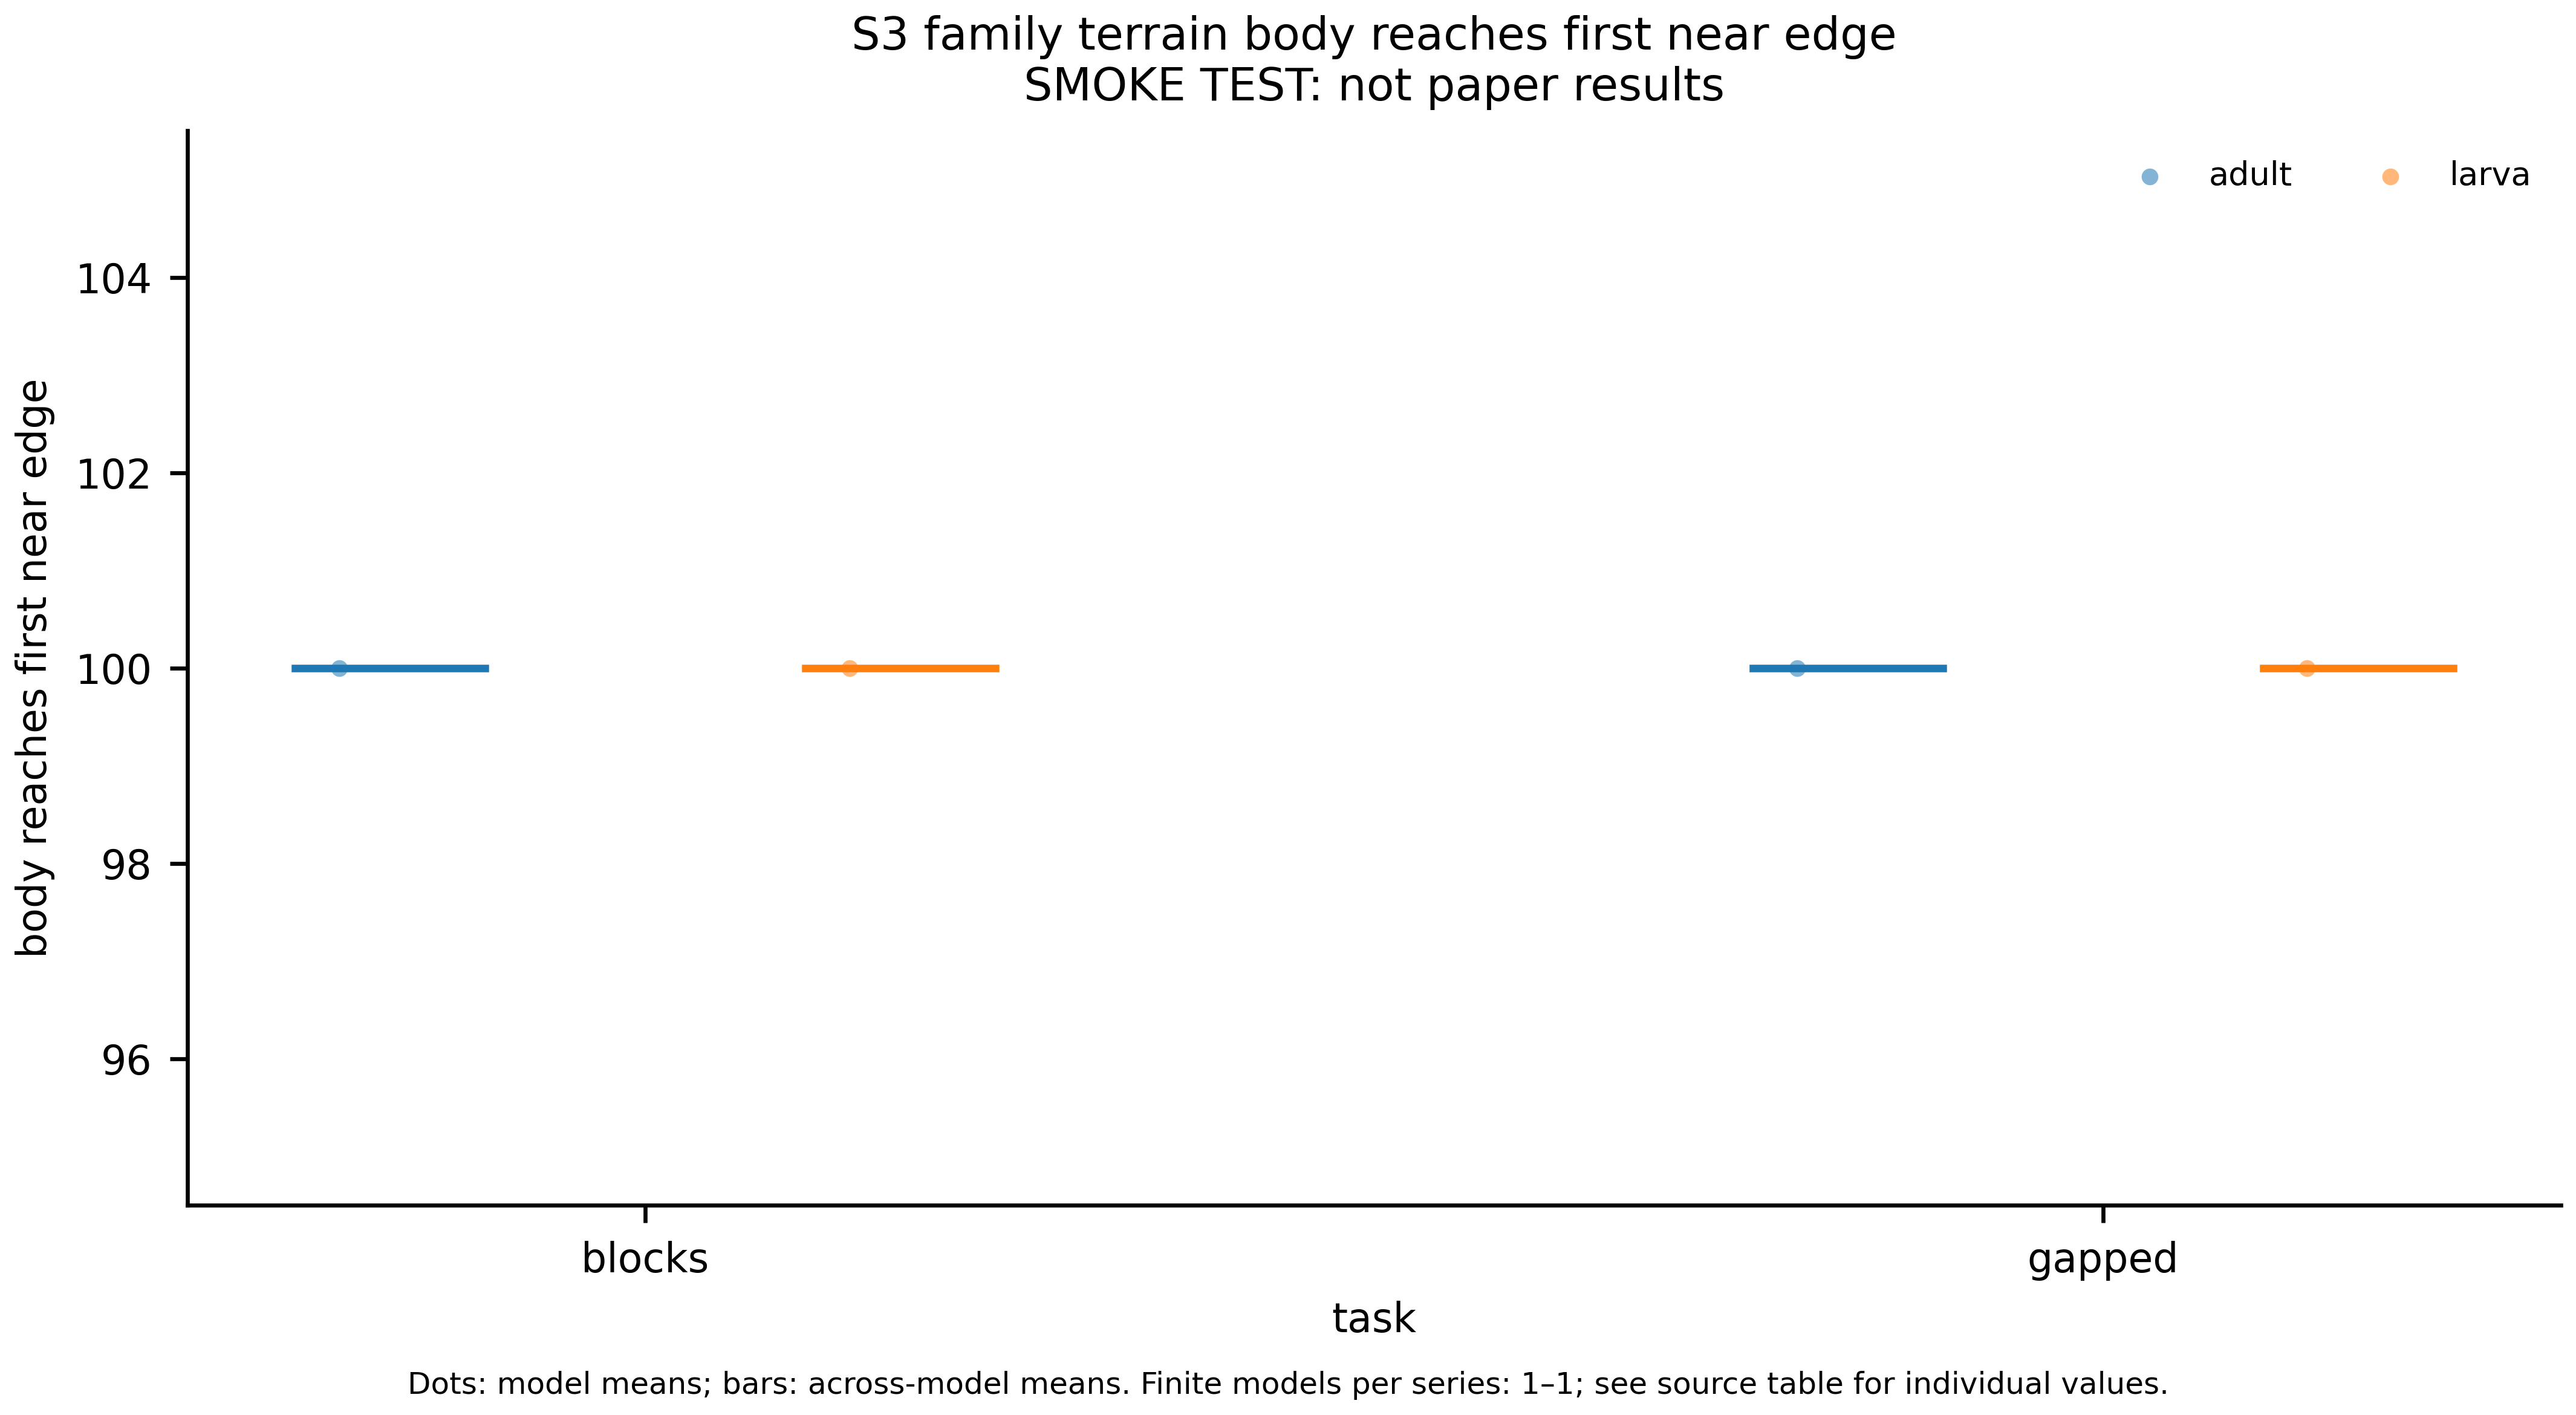

`figures/paper/S3_family_terrain_forward_distance_mm.png`

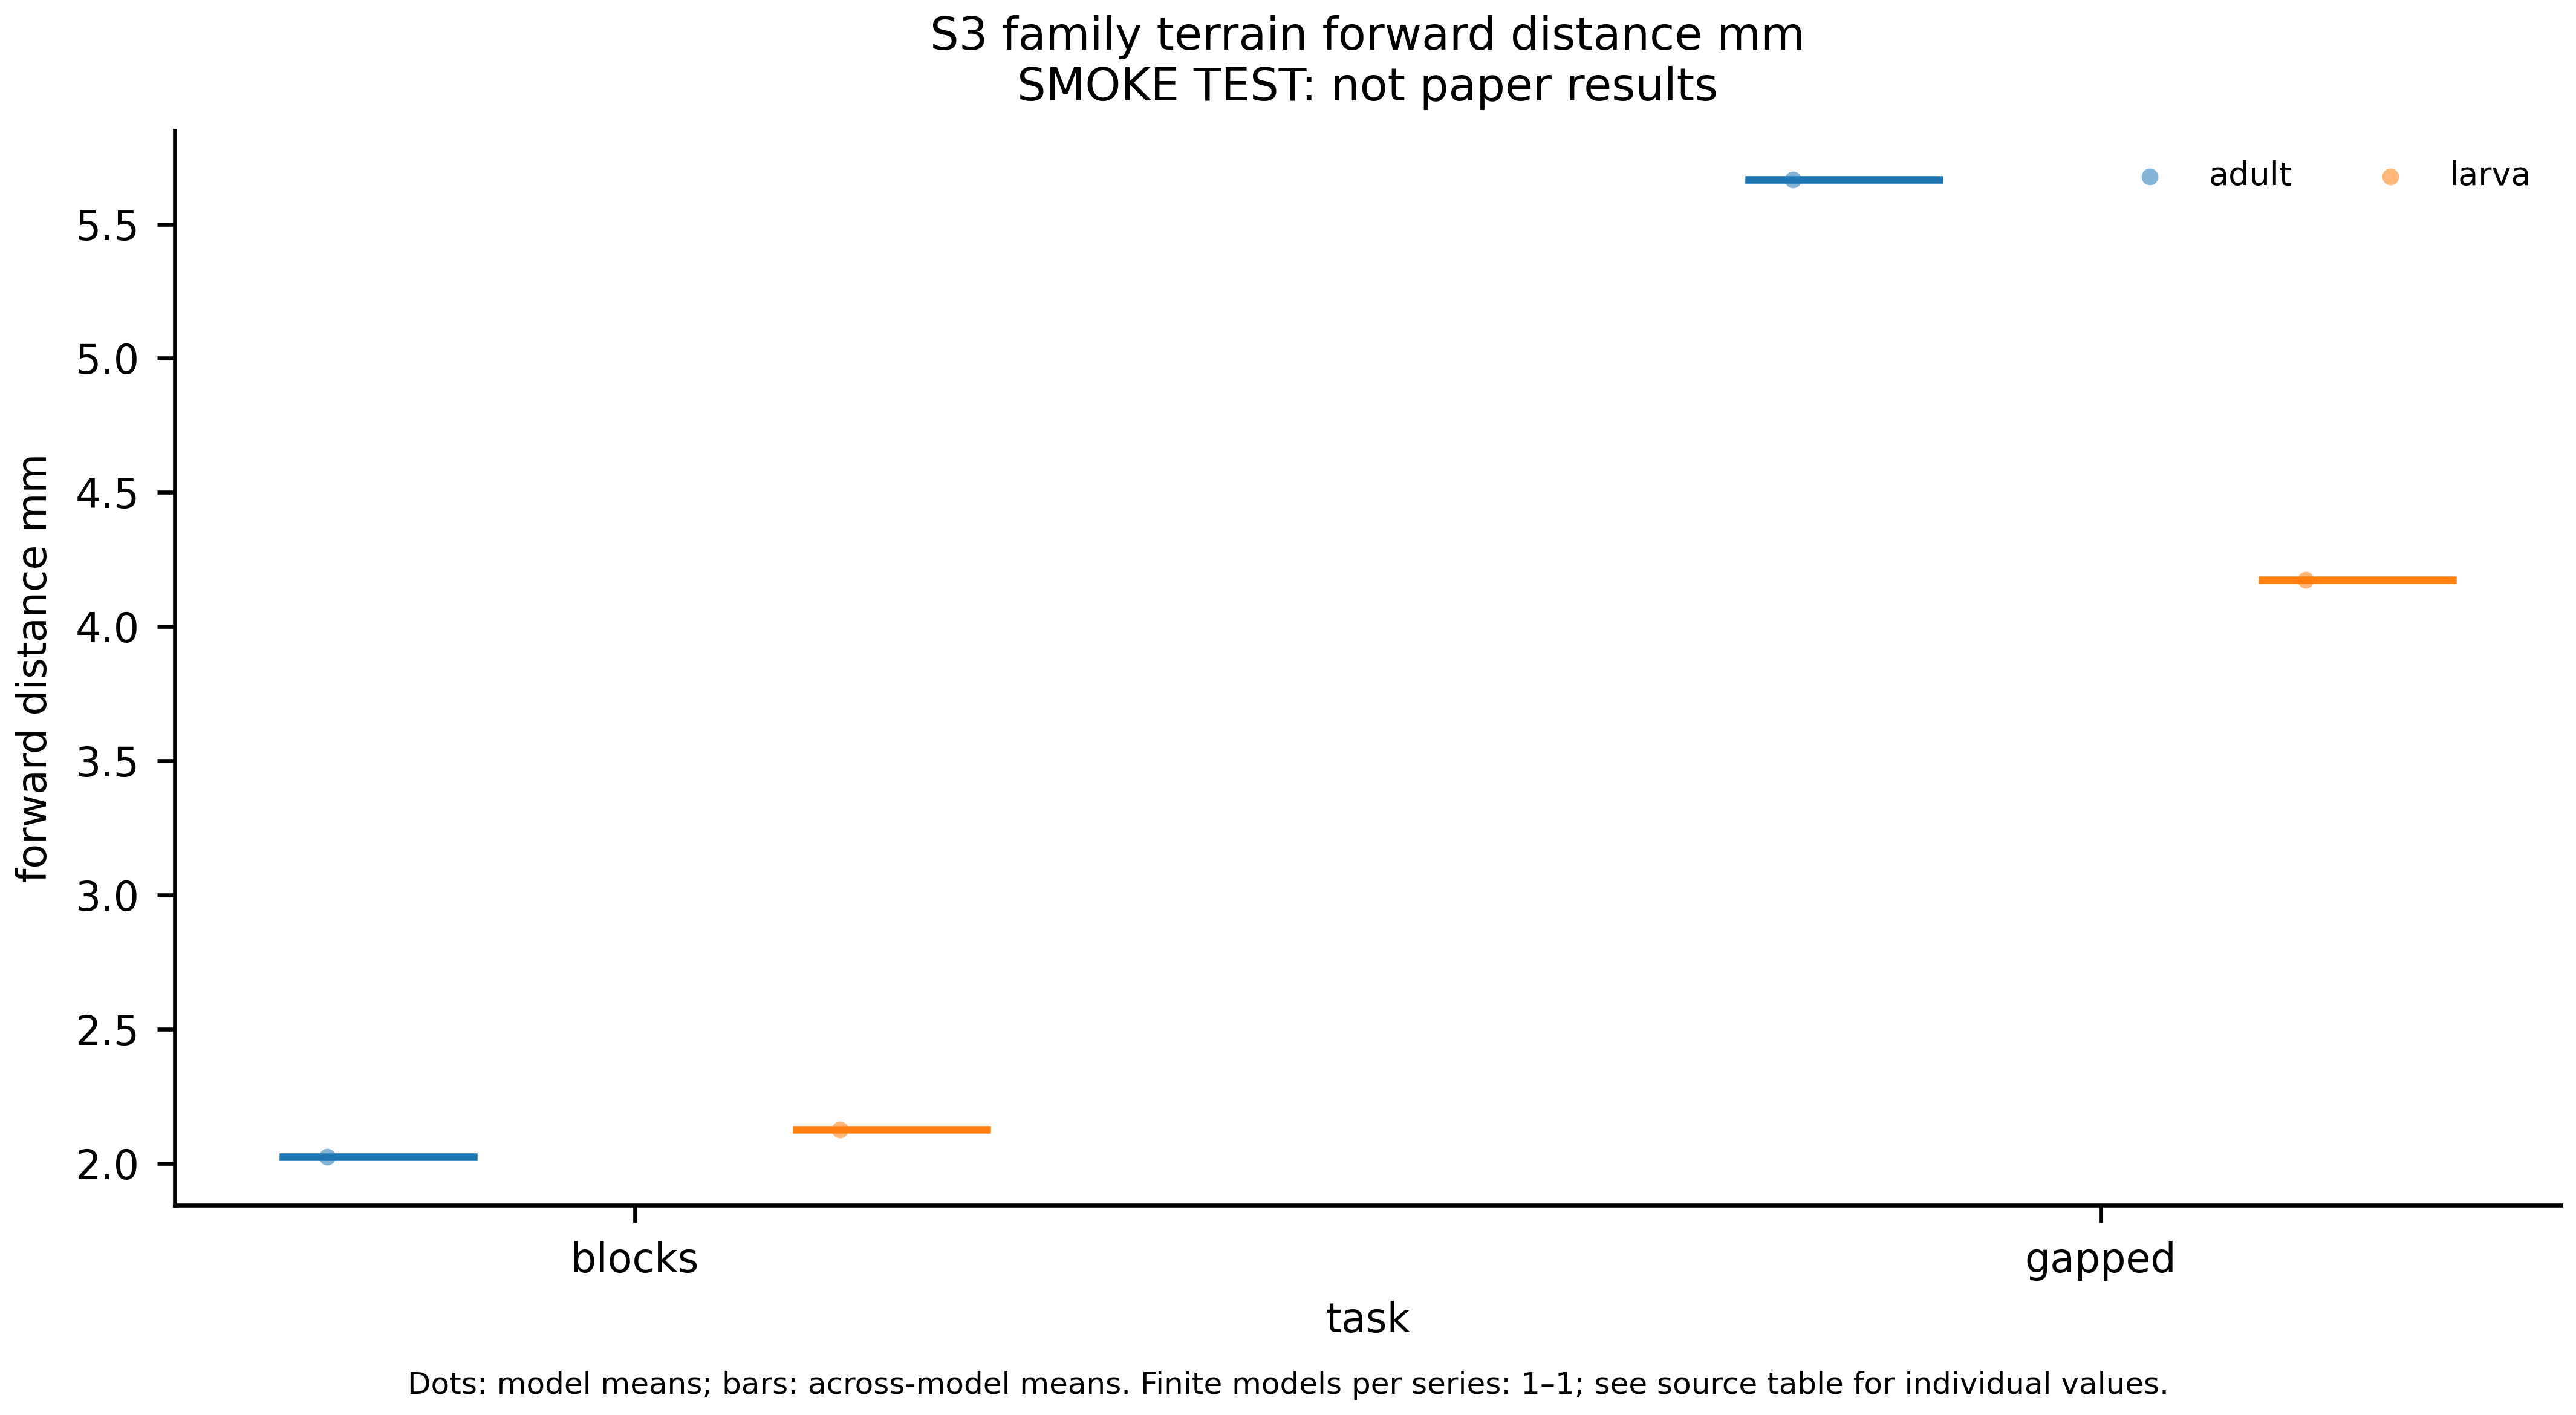

`figures/paper/S3_family_terrain_max_lateral_mm.png`

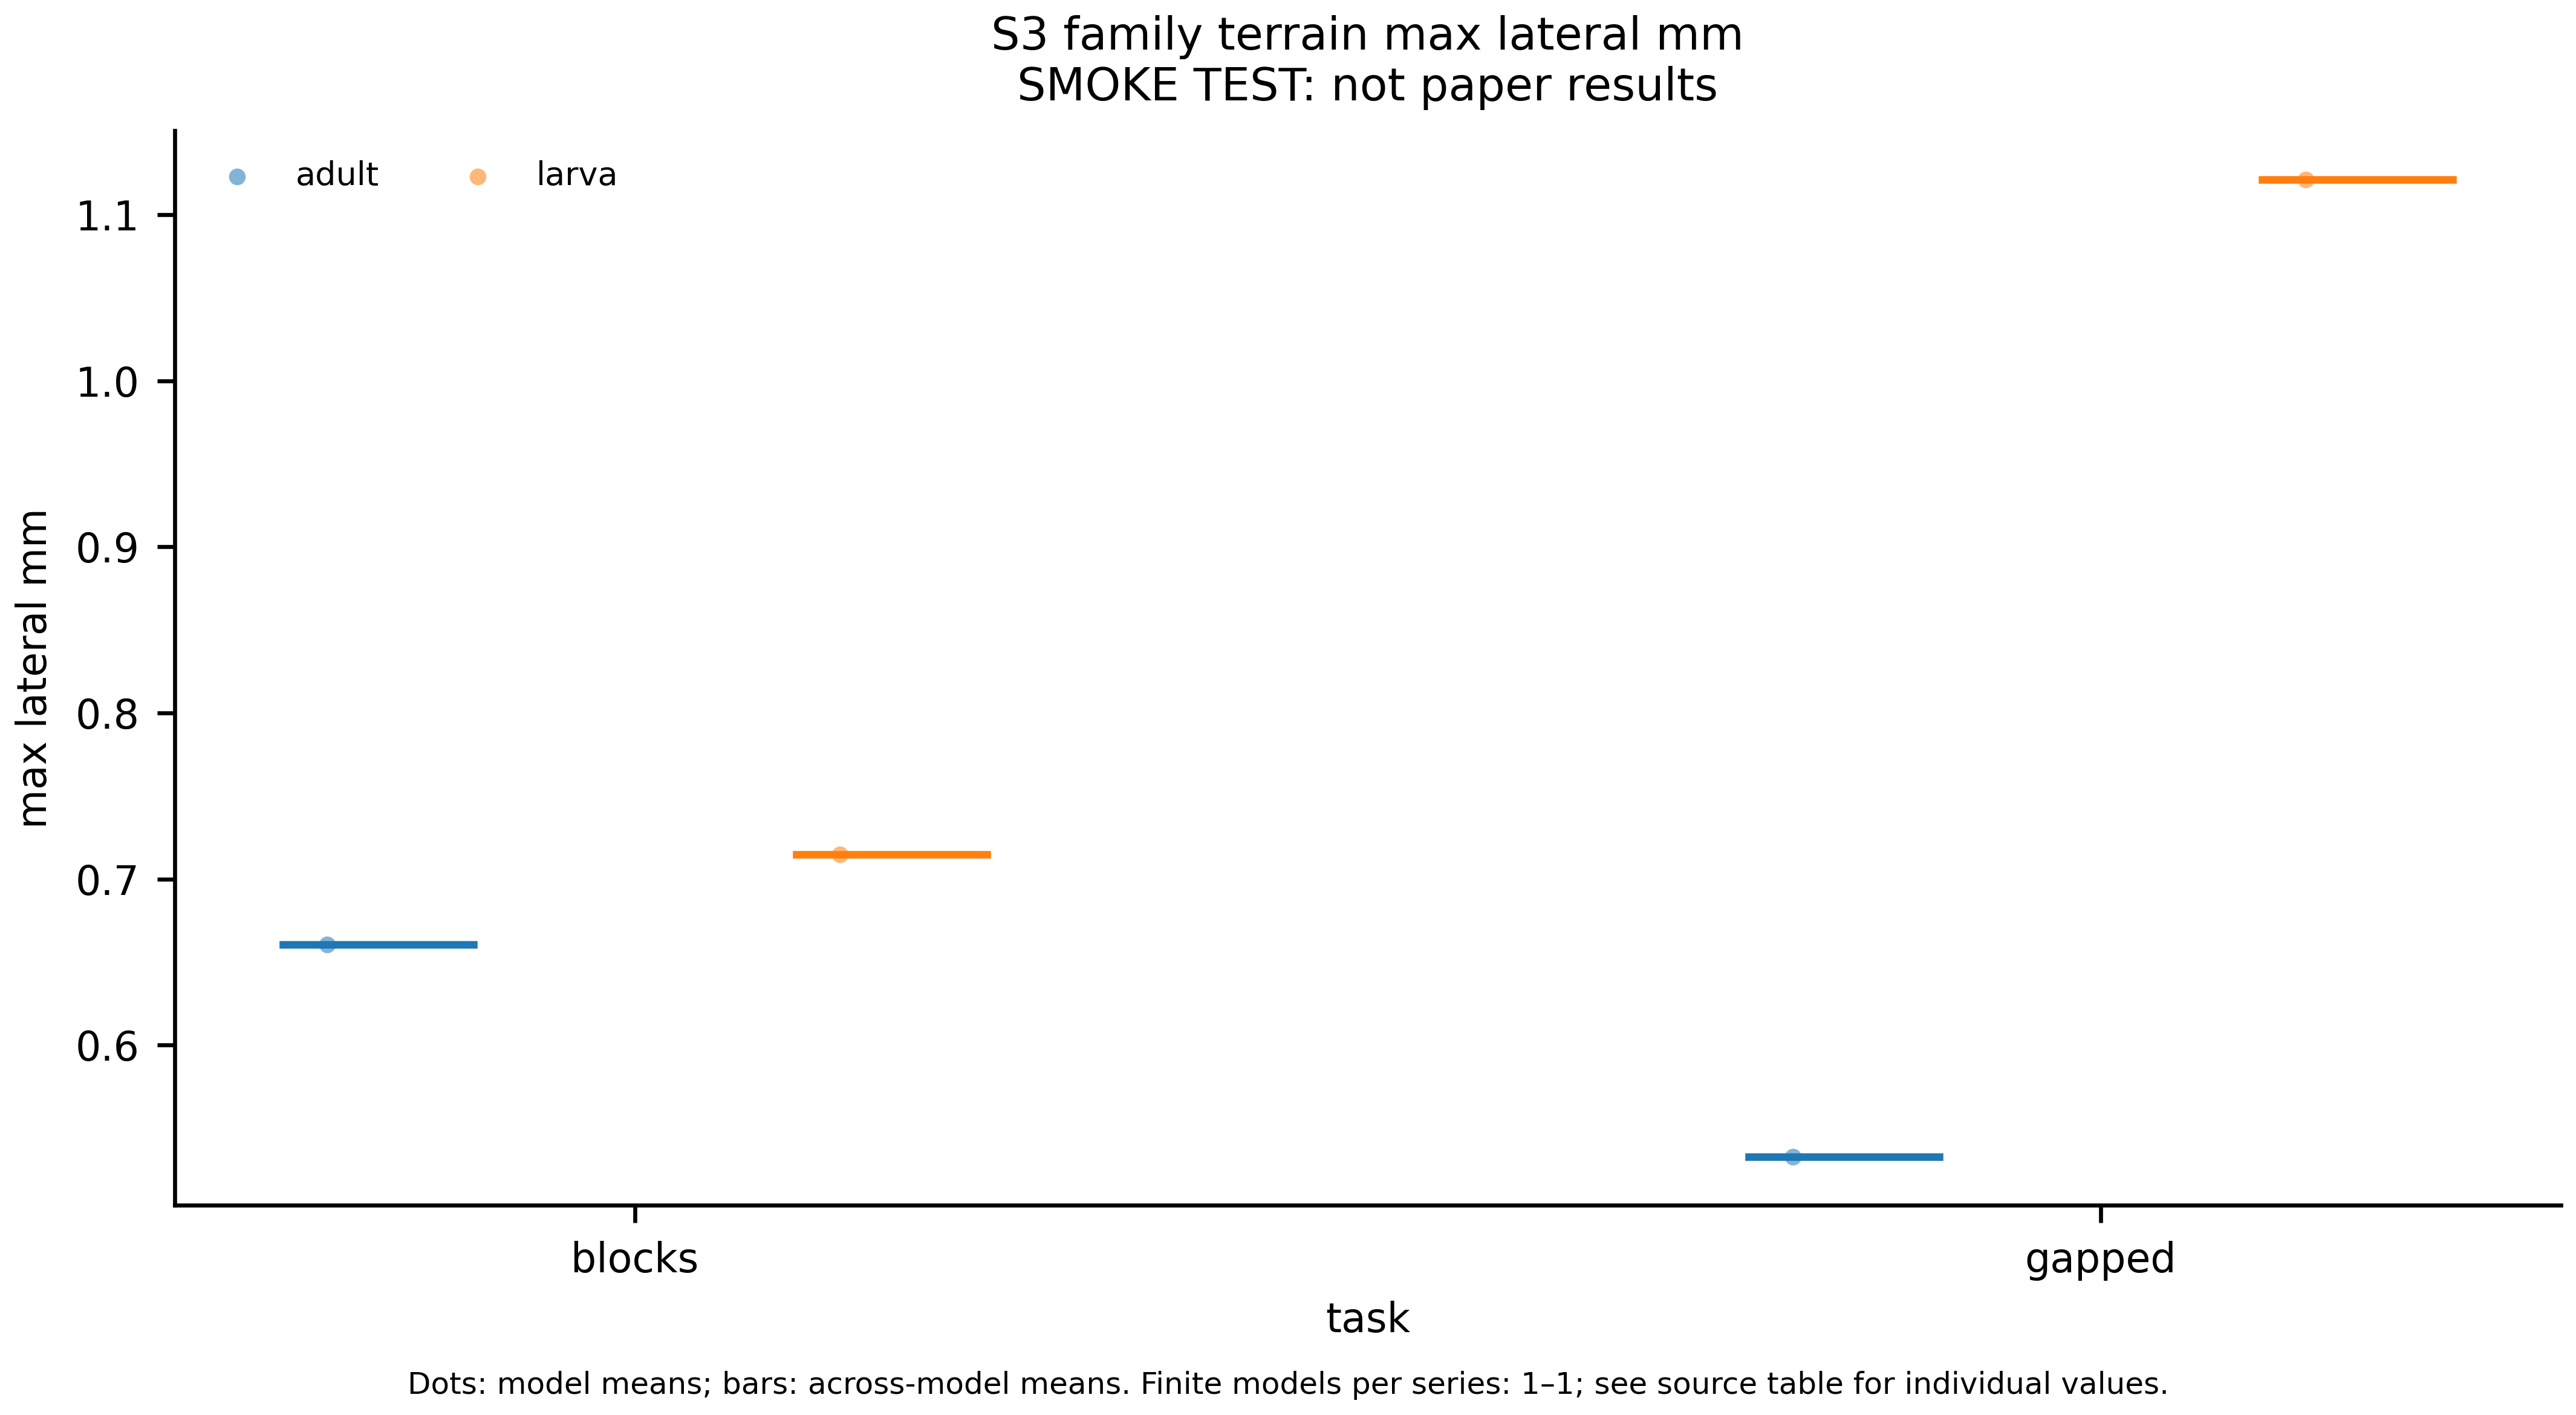

The complete numerical files and figures are saved in `RUN_DIR`. The tables and images displayed here are embedded in this notebook.

In [8]:
show_outputs(RUN_DIR)

## Full reproduction

Run this command in a terminal from the repository root, with the environment activated:

```bash
python scripts/S03_development_terrain.py --run-dir runs/development-terrain --device cuda:0 --workers 4
```

Equivalent command:

```bash
flycontrol run --config development-terrain --run-dir runs/development-terrain --device cuda:0 --workers 4
```

Use an available CUDA device, or `cpu`. Without `--smoke`, the script uses the complete fixed seed cohort, training budgets and condition grids. Keep full outputs in a separate run directory. These commands are documentation only; **Run All never launches the full campaign**.

After both full developmental runs finish, combine the complete 22-comparison family:

```bash
flycontrol combine-development --terrain runs/development-terrain --turning runs/development-turning --output runs/development-combined
```
